# Mobile Robotic project

## Camera and Thymio connexion 

#### First Priority:
- Visualization of ekf in plots after main loop -> Linus
- Explain more how we get ekf tuning in ```scripts/filtering_test.ipynb``` -> Linus
- Write report -> everyone

#### Other:
- TBD: Visualization of ekf covariance on video feed (more important for live demo) 
- Clean up all the scripts -> everyone
- Generate nice figures for the report
- Go over all code with unified documentation and make some parts look less like chatgpt ;)
- Update ```requirements.txt```
- Adapt Vision to enable new obsacle without removing robot and goal ?
- Put more stats live on the image or next to it / elipse that show the covariance of the EKF

### Done:
- Add local navigation to main loop and test - DONE (not perfect)
- Fix the line following bug  - DONE

In [1]:
%reload_ext autoreload
%autoreload 2
# Get frames to auto-adjust camera and get fps

import sys
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('./src')
from src.vision import Vision 
from src.vision import Camera
from src.thymio import ThymioClient
from src.global_navigation import GlobalNavigation
from src.local_navigation import LocalNavigation
from src.filtering import ExtendedKalmanFilter
from src.filtering import CoordinateTransform2D
from src.filtering import WheelSpeedTransform
from src.control import Control
from src.draw_plot_utils import *

# Reset thymio in case kernel crashed on last run
thymio = ThymioClient()
thymio.set_motors(0, 0)
thymio.close()

Client created and connected to Thymio.
Stopping Thymio client and unlocking robot.


Initialize all modules:

In [2]:
cam_id = 1
cam = Camera(cam_id)

vision = Vision()

ekf = ExtendedKalmanFilter()
nav = GlobalNavigation()
control = Control()
local_nav = LocalNavigation()

Camera with ID 1 opened successfully.
Camera thread launched


Let the Camera adjust and setup the vision module (transforms and warp):

Camera fps:  0.0
Detected markers: {23: (566.0, 366.0), 69: (63.0, 373.0), 42: (95.0, 52.0), 30: (537.0, 47.0)}
Map size in pixels: width = 442.0 , height = 319.0
Pixels per cm: 4.20952380952381


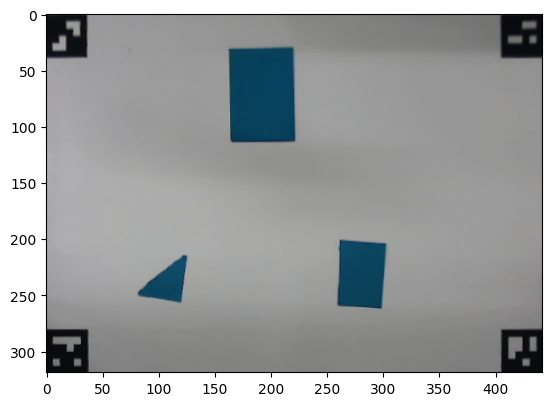

In [ ]:
# Let Camera adjust
cv2.namedWindow("output", cv2.WINDOW_NORMAL)

while True:

    ret, frame = cam.get_frame()

    if not ret:
        print("Error: Could not read frame.")
        break

    cv2.imshow("output", frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cv2.destroyAllWindows()

# Initialize vision
test_frame = vision.setup(frame)
test_frame = cv2.cvtColor(test_frame, cv2.COLOR_BGR2RGB)

plt.imshow(test_frame)
plt.show()

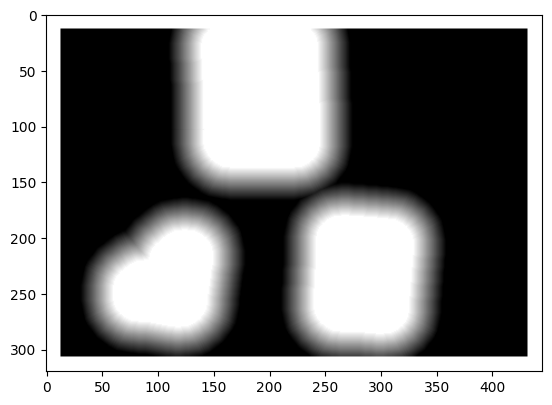

In [4]:
ret, frame = cam.get_frame()

# Get occupancy grid:
grid = vision.get_occupancy_grid(frame,is_marker_in_corners=True,debug=False)

plt.imshow(grid, cmap="gray")
plt.show()

Initialize Coordinate transforms:

In [5]:
px_per_cm = vision.pixels_per_cm
px_per_mm = px_per_cm / 10

MAP_HEIGHT_MM = 600
THYMIO_TO_MM_SEC_LEFT = 100 / 29.2 
THYMIO_TO_MM_SEC_RIGHT = 100 / 28.8

tf = CoordinateTransform2D(px_per_mm, MAP_HEIGHT_MM)
speed_t = WheelSpeedTransform(THYMIO_TO_MM_SEC_LEFT, THYMIO_TO_MM_SEC_RIGHT)

Main loop of the robot:

**Ideas:**
- Plot the planned paths only at the end of the loop to avoid lags (plot currently commented)
- Plot ekf covariance elipse also on the cv2 image if it does not overcrowd the visualization
- 

In [42]:
ekf.clear_history()
try:# Create a window for drawing and start Thymio Client
    cv2.namedWindow("output", cv2.WINDOW_NORMAL)
    thymio = ThymioClient()

    cv2.imshow("output", frame)

    # Hold window until user presses 's' to allow resizing
    while False:
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    KIDNAP_THRESH = 70   # Keep at 70 and lift high if black should be ignored
    TIMEOUT_CYCLES = 30

    # Robot State variables
    PLAN_PATH = True
    TIMEOUT = False

    timeout_count = 0
    countdown = 0
    old_left_wheel_speed = 0
    old_right_wheel_speed = 0

    ### Main loop: run until goal is reached
    while True:

        loop_start = time.time()

        # Get a new camera frame:
        ret, frame = cam.get_frame()

        if not ret:
            print("Error: could not read camera frame")
            continue # maybe break

        # Plan a path if necessary:
        if PLAN_PATH:
            print("Plan new path")
            got_loc, pose, _ = vision.localize_robot(frame)
            got_goal, goal_pos = vision.get_goal_position(frame)

            if not got_loc:
                print("Error: could not localize robot during planning")
                continue # maybe break
            if not got_goal:
                print("Error: could not localize goal during planning")
                continue  # maybe break

            # Plan and smooth the path
            path, explored, exporation_count = nav.grid_search_astar(Map=grid, S=pose, G=goal_pos)
            smooth_path = nav.grid_path_smoothing(path=path, Map=grid)
            
            if path is None or len(path) == 0:
                print("Error: could not find a path to the goal")
                continue # maybe break

            # Initialize EKF at robot position
            pose_ekf = tf.vision_to_ekf(pose)
            ekf.init_state(pose_ekf)

            print("Path planned successfully")
            PLAN_PATH = False

        # Get robot sensors:
        prox, v_l, v_r, ground = thymio.get_measurements()

        # Detect Kidnaping:
        if ground[0] < KIDNAP_THRESH and ground[1] < KIDNAP_THRESH and not TIMEOUT:
            # TODO: maybe here wait one tour and measure again if we have false positives
            # -> worked well til now

            print("Robot got kidnaped")
            thymio.set_motors(0, 0)
            
            TIMEOUT = True

        # Drive to target if not in timeout:
        if not TIMEOUT:

            # EKF predict step + visualization:
            v_l_ekf, v_r_ekf = speed_t.thymio_to_mmsec(v_l, v_r)
            ekf.predict(v_r_ekf, v_l_ekf)

            # EKF update step:
            got_loc, pose, frame_crop = vision.localize_robot(frame)

            if got_loc:
                pose_ekf = tf.vision_to_ekf(pose)
                ekf.update(pose_ekf, save_history=True)

            ekf_pose, ekf_cov = ekf.get_state_cov(save_history=True)
            ekf_pose_img = tf.ekf_to_vision(ekf_pose)
            ekf_cov_img = tf.cov_ekf_to_vision(ekf_cov[:2,:2])
            
            # Follow the path
            closest_point = nav.find_closest_point_smoothed_path(ekf_pose_img, smooth_path)
            
            if closest_point is None:
                print("Error: no closest point found on path.")
                continue

            ret = nav.target_point(closest_point_on_path=closest_point, look_ahead_distance=10*px_per_cm,
                                    path=smooth_path, return_angles=True)
            target_y_x, angle_segment = ret

            # Calculate and set wheel speeds
            px_per_m = px_per_cm * 100
            target_meters = [target_y_x[1]/px_per_m, target_y_x[0]/px_per_m, angle_segment]
            pose_ekf_img_meters = [ekf_pose_img[0]/px_per_m, ekf_pose_img[1]/px_per_m, ekf_pose_img[2]]
            left_wheel_speed, right_wheel_speed = control.control(robot_pose=pose_ekf_img_meters,
                                                                    goal_pose=target_meters)
            

            condition = (np.array(prox)>2000).any()
            if condition:
                direction_x, direction_y = local_nav.compute(prox, state=True)
                print(f"Local navigation activated: direction_x: {direction_x}, direction_y: {direction_y}")
                gain_x = -10
                gain_global = 40
                left_wheel_speed =  direction_x * gain_x + gain_global + 20 # +20 to avoid getting stuck
                right_wheel_speed =  - direction_x * gain_x + gain_global
                old_left_wheel_speed = left_wheel_speed
                old_right_wheel_speed = right_wheel_speed
                countdown = 50
            
            if countdown > 0 and not condition:
                countdown -= 1
                sens = np.sign(direction_x)
                # if countdown > 30:
                #     left_wheel_speed = sens * 30 + 50
                #     right_wheel_speed = - sens * 30 + 50
                # elif countdown > 10:
                if countdown > 30:
                    left_wheel_speed = 80
                    right_wheel_speed = 80
                elif countdown > 20:
                    left_wheel_speed =  sens * 40 + 50
                    right_wheel_speed = - sens * 40 + 50
                elif countdown > 1:
                    left_wheel_speed = 80
                    right_wheel_speed = 80
                elif countdown == 1:
                    PLAN_PATH = True


            thymio.set_motors(int(right_wheel_speed), int(left_wheel_speed))

        # Handle timeout counter
        else:
            if timeout_count > TIMEOUT_CYCLES:
                TIMEOUT = False
                PLAN_PATH = True
                timeout_count = 0
            else:
                timeout_count += 1
                frame_crop = vision._cut_frame_to_world(frame)
                cv2.putText(frame_crop, f"KIDNAPED!", (155, 280), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 3)

        # Visualize everything # TODO: clean up  
        draw_path(frame_crop, smooth_path, (0, 255, 0))
        draw_point(frame_crop, closest_point, (255, 0, 255))
        draw_pose(frame_crop, ekf_pose_img, (0, 255, 255))
        draw_covariance(frame_crop, ekf_pose_img, ekf_cov_img, (0, 255, 255)) 
            
        target_x_y = (target_y_x[1], target_y_x[0])
        draw_point(frame_crop, target_x_y, (0, 165, 255))

        distance_to_goal = np.hypot(ekf_pose_img[0] - goal_pos[0], ekf_pose_img[1] - goal_pos[1]) / px_per_cm
        cv2.putText(frame_crop, f"Distance to goal: {distance_to_goal:.2f} cm", (40,30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 2)
        # superpose the grid on the frame_crop
        grid_color = cv2.cvtColor(grid, cv2.COLOR_GRAY2BGR)
        grid_color = cv2.resize(grid_color, (frame_crop.shape[1], frame_crop.shape[0]))
        grid_color = cv2.bitwise_not(grid_color)
        transparency = 0.25
        cv2.addWeighted(grid_color, transparency, frame_crop, 1 - transparency, 0, frame_crop)
        
        # Stop the loop if goal is reached
        if cv2.waitKey(1) & 0xFF == ord('q') or distance_to_goal < 2:
            if distance_to_goal < 2:
                cv2.putText(frame_crop, f"GOAL REACHED!", (115, 280), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 3)
                print("Reached goal!")
                cv2.imshow("output", frame_crop)
            break

        cv2.imshow("output", frame_crop)

        # Wait until next iteration
        # loop_delta_t = time.time() - loop_start
        # print(f"Loop delta t: {loop_delta_t}")
        # thymio.wait(D_T)

    ### Once the goal is reached:

    # Stop robot
    thymio.set_motors(0,0)

    # Loop to keep window alive until user closes it
    # TODO: discuss if we want to keep this
    while True:
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
    cv2.destroyAllWindows()
    thymio.close()
except Exception as e:
    # After the loop stop thymio and close all windows
    cv2.destroyAllWindows()
    thymio.set_motors(0,0)
    thymio.close()
    print("An error occurred:", e)

Client created and connected to Thymio.
Plan new path
Path planned successfully
Reached goal!
Stopping Thymio client and unlocking robot.


Print the EKF stats:

**I want:**
- One plot with the position and covariance ellipses (in EKF frame because plt)
- One errorbar plot with covariance of the heading

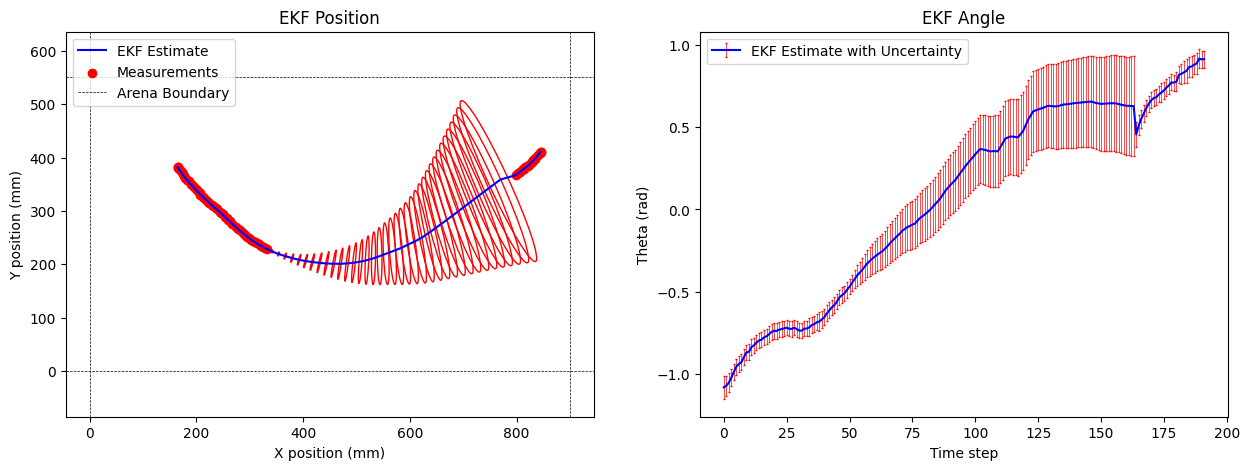

In [43]:
# Plot the results
pose_hist, cov_hist, meas_hist = ekf.get_history()

pose_hist = np.array(pose_hist)
meas_hist = np.array(meas_hist)
cov_hist = np.array(cov_hist)

plt.figure(figsize=(15,5))
ax = plt.subplot(1, 2, 1)
plt.plot(pose_hist[:,0], pose_hist[:,1], label="EKF Estimate", color="blue")
plt.scatter(meas_hist[:,0], meas_hist[:,1], label="Measurements", color="red")
for i, cov in enumerate(cov_hist):
    if i%3 == 0:
        plot_covariance_ellipse(pose_hist[i][:2], cov[:2, :2], ax, fc="none", ec="red")
plt.xlabel("X position (mm)")
plt.ylabel("Y position (mm)")
plt.axvline(x=0, color='black', linewidth=0.5, ls='--', label="Arena Boundary")
plt.axhline(y=0, color='black', linewidth=0.5, ls='--')
plt.axvline(x=900, color='black', linewidth=0.5, ls='--')
plt.axhline(y=550, color='black', linewidth=0.5, ls='--')
# Set arena limits
plt.title("EKF Position")
plt.legend(loc='upper left')
plt.axis('equal')

plt.subplot(1, 2, 2)
plt.errorbar(range(len(pose_hist[:,2])), pose_hist[:,2],
             yerr= np.array([np.sqrt(cov[2,2]) for cov in cov_hist]),
             label="EKF Estimate with Uncertainty", color="blue", ecolor='red', elinewidth=0.5, capsize=1)
plt.xlabel("Time step")
plt.ylabel("Theta (rad)")
plt.title("EKF Angle")
plt.legend()

plt.savefig("ekf_results_2.png")
plt.show()

Shut down the camera thread:

In [25]:
cam.stop()

Camera with ID 4 released, thread stopped
